# 04 · Player EDA

**Question: how is each player performing?**

Player-match statistics are built from the event stream with the shared
metric definitions in `barca.analytics.definitions`, and minutes played come
from lineup spells including stoppage time. This notebook:

1. shows why per-90 rates need a minimum-minutes threshold;
2. explores attacking output, possession and progression, and defending;
3. adjusts defensive numbers for possession, which matters enormously for
   a team that averages about 65% of the ball;
4. builds position-group profiles, the raw material for the player rating
   (BIPR, milestone 10).

$$ Metric_{90} = \frac{Metric}{Minutes}\times 90 $$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca import config, pipeline
from barca.analytics import player_match, player_season, team_match
from barca.data import normalize
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(2)

matches = normalize.matches(pl.read_parquet(config.INTERIM / "matches.parquet"))
events = normalize.events(pipeline.scan_events())
lineups = pl.read_parquet(config.INTERIM / "lineups.parquet")
positions = pl.read_parquet(config.INTERIM / "positions.parquet")
minutes = normalize.player_minutes(positions, normalize.period_bounds(events))
tms = team_match.team_match_stats(events, matches)
pm = player_match.player_match_stats(events, minutes, matches, lineups)
pm = player_season.possession_adjust(pm, tms.select("match_id", "team_id", "possession"))
barca_pm = pm.filter(pl.col("team") == "Barcelona")
print(f"player-match rows: {pm.height:,} · Barcelona: {barca_pm.height:,} · Barcelona players: {barca_pm['player_id'].n_unique()}")

player-match rows: 24,234 · Barcelona: 7,318 · Barcelona players: 125


## 1. Why a minimum-minutes threshold?

A substitute who scores in a 10-minute cameo has 9 goals per 90. Per-90
rates are only meaningful with enough minutes behind them. The funnel below
plots every Barcelona player-season: rates at low minutes are wildly
dispersed, and they settle down as minutes accumulate.

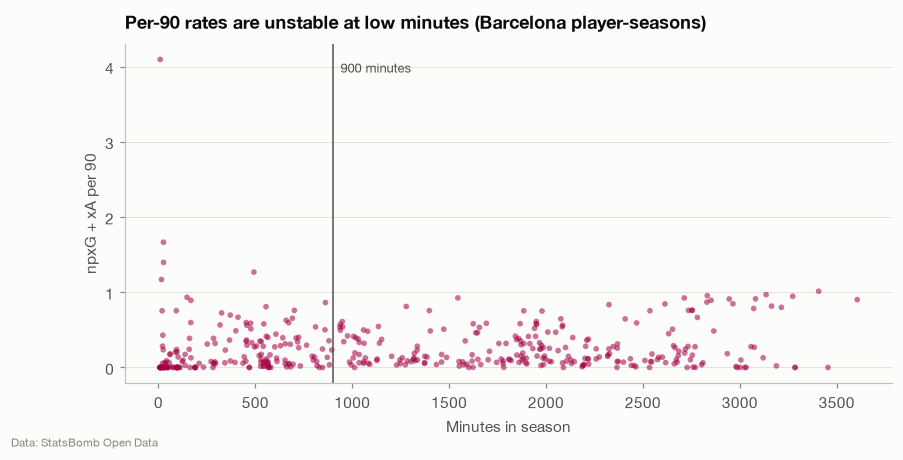

player-seasons: 412 · with ≥900 minutes: 239


In [2]:
seasons = player_season.aggregate(barca_pm, ["season", "player_id"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(seasons["minutes"], seasons["npxg_xa_p90"], s=14, color=style.BARCA, alpha=0.55, edgecolor="none")
ax.axvline(player_season.MIN_MINUTES_SEASON, color=style.INK_2, lw=1)
ax.annotate("900 minutes", (player_season.MIN_MINUTES_SEASON, ax.get_ylim()[1] * 0.95), xytext=(5, 0),
            textcoords="offset points", fontsize=8.5, color=style.INK_2, va="top")
ax.set_xlabel("Minutes in season")
ax.set_ylabel("npxG + xA per 90")
ax.set_title("Per-90 rates are unstable at low minutes (Barcelona player-seasons)")
style.caption(ax, style.STATSBOMB_CREDIT)
style.savefig(fig, "04_minutes_funnel")
plt.show()
print("player-seasons:", seasons.height, "· with ≥900 minutes:", seasons.filter(pl.col("minutes") >= 900).height)

Below roughly 900 minutes (ten full matches) the spread is dominated by
noise. **Season-level comparisons use ≥ 900 minutes and career-level ones
≥ 1,800.** Players below the threshold are still shown in the app, with a
low-sample warning instead of a rating.

## 2. Who played?

In [3]:
career = player_season.aggregate(barca_pm, ["player_id"])
career.sort("minutes", descending=True).select(
    "display_name", "position_group", "appearances", "starts", "minutes", "goals", "assists", "xg", "xa",
).head(20)

display_name,position_group,appearances,starts,minutes,goals,assists,xg,xa
str,str,u32,u32,f64,u32,u32,f32,f32
"""Lionel Messi""","""W""",522,465,44342.03,474,186,324.87,142.64
"""Sergio Busquets""","""DM""",389,344,31270.48,8,30,6.27,23.04
"""Gerard Piqué""","""CB""",334,322,29975.63,25,4,26.61,7.58
"""Andrés Iniesta""","""CM""",334,263,24551.22,24,58,28.25,43.44
"""Víctor Valdés""","""GK""",254,253,23850.87,0,0,0.00,0.98
"""Xavi""","""CM""",263,230,21158.63,36,68,25.31,56.95
"""Jordi Alba""","""FB""",239,222,20922.62,12,40,11.98,32.82
"""Dani Alves""","""FB""",228,209,19702.83,14,58,9.32,43.60
"""Javier Mascherano""","""CB""",192,169,15907.08,1,2,1.99,3.66


## 3. Attacking output

Non-penalty xG plus xA per 90 measures a player's direct involvement in
chances, as the shooter or as the creator. Barcelona player-seasons with
≥ 900 minutes:

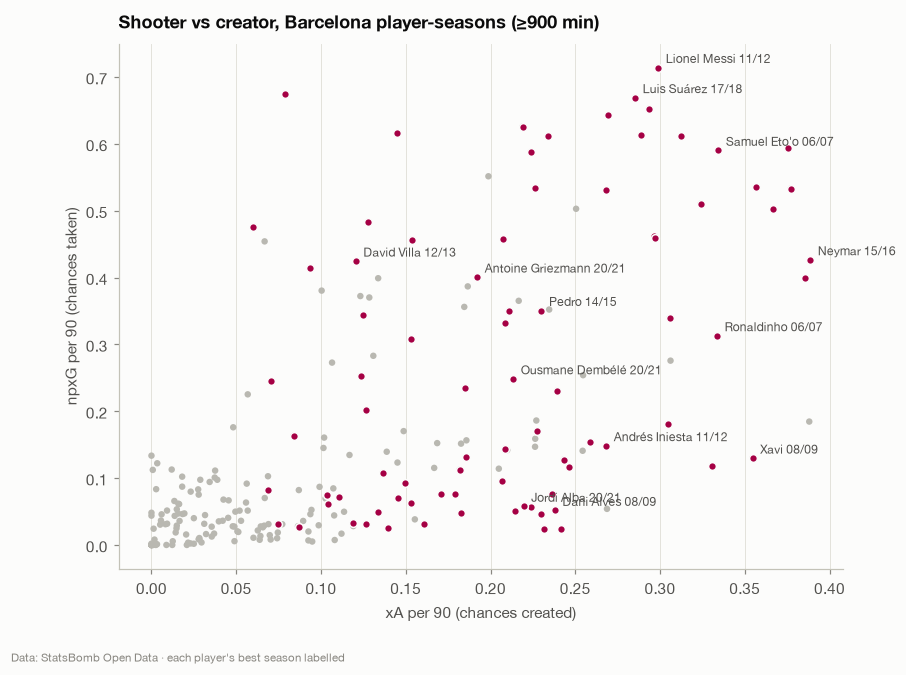

In [4]:
q = seasons.filter(pl.col("minutes") >= 900)
fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.scatter(q["xa_p90"], q["npxg_p90"], s=18, color=style.NEUTRAL, edgecolor="none", zorder=2)
highlight = ["Lionel Messi", "Luis Suárez", "Neymar", "Samuel Eto'o", "David Villa", "Andrés Iniesta",
             "Xavi", "Dani Alves", "Ronaldinho", "Pedro", "Antoine Griezmann", "Ousmane Dembélé", "Jordi Alba"]
h = q.filter(pl.col("display_name").is_in(highlight))
ax.scatter(h["xa_p90"], h["npxg_p90"], s=26, color=style.BARCA, edgecolor=style.SURFACE, linewidth=1, zorder=3)
best = h.sort("npxg_xa_p90", descending=True).group_by("display_name", maintain_order=True).first()
for r in best.iter_rows(named=True):
    ax.annotate(f"{r['display_name']} {r['season'][2:4]}/{r['season'][7:9]}", (r["xa_p90"], r["npxg_p90"]),
                xytext=(5, 3), textcoords="offset points", fontsize=8, color=style.INK_2)
ax.set_xlabel("xA per 90 (chances created)")
ax.set_ylabel("npxG per 90 (chances taken)")
ax.set_title("Shooter vs creator, Barcelona player-seasons (≥900 min)")
ax.grid(axis="both")
style.caption(ax, style.STATSBOMB_CREDIT + " · each player's best season labelled")
style.savefig(fig, "04_npxg_vs_xa")
plt.show()

Messi's seasons fill the top-right corner, elite on *both* axes, joined
only by the best seasons of Suárez and Eto'o. Neymar's 2015/16 is the most
creative forward season outside Messi's. Xavi, Iniesta and the full-backs
Dani Alves and Jordi Alba sit low and to the right: pure creators.

### Finishing: goals above expected

Career non-penalty goals minus npxG, for players with at least 20 npxG:

In [5]:
fin = (
    career.filter(pl.col("npxg") >= 20)
    .select("display_name", "minutes", "np_goals", "npxg", "np_goals_minus_npxg",
            (pl.col("np_goals") / pl.col("npxg")).alias("goals_per_xg"))
    .sort("np_goals_minus_npxg", descending=True)
)
fin

display_name,minutes,np_goals,npxg,np_goals_minus_npxg,goals_per_xg
str,f64,u32,f32,f64,f64
"""Lionel Messi""",44342.03,414,266.89,147.11,1.55
"""Luis Suárez""",15872.33,129,101.00,28.00,1.28
"""Samuel Eto'o""",6764.60,63,46.86,16.14,1.34
"""Pedro""",11444.75,49,37.25,11.75,1.32
"""Xavi""",21158.63,36,25.31,10.69,1.42
"""David Villa""",4723.52,32,22.53,9.47,1.42
"""Thierry Henry""",4714.67,33,24.03,8.97,1.37
"""Neymar""",9720.90,56,47.50,8.50,1.18
"""Gerard Piqué""",29975.63,25,26.61,-1.61,0.94


Messi alone accounts for about half of Barcelona's total over-performance
of xG. Almost every high-volume Barcelona forward finishes above
expectation, which is consistent with the club recruiting elite finishers.
Whether that is *skill* or *luck* can be judged by persistence: does a
player's over-performance in one season predict the next?

In [6]:
persist = (
    seasons.filter(pl.col("npxg") >= 3)
    .sort("player_id", "season")
    .with_columns(
        (pl.col("np_goals") / pl.col("npxg")).alias("ratio"),
        pl.col("np_goals").shift(-1).over("player_id").alias("next_goals"),
        pl.col("npxg").shift(-1).over("player_id").alias("next_npxg"),
        pl.col("season").shift(-1).over("player_id").alias("next_season"),
    )
    .drop_nulls("next_goals")
    .with_columns((pl.col("next_goals") / pl.col("next_npxg")).alias("next_ratio"))
)
print(f"pairs of consecutive seasons: {persist.height}")
print(f"year-to-year correlation of goals/npxG: {persist.select(pl.corr('ratio', 'next_ratio')).item():.2f}")

pairs of consecutive seasons: 50
year-to-year correlation of goals/npxG: -0.11


Season to season, finishing ratio shows **no persistence** at all (a
correlation around zero over 50 consecutive-season pairs). Over a single
season, over- or under-performing xG is mostly noise. Over a career it is a
different story: Messi's +147 goals from 267 npxG (1.55 goals per xG) is
far beyond what noise can produce. The practical rule for the models: **xG
is the stable short-term signal**, and finishing skill only shows up over
very large samples, so it enters as a slow, long-window feature (team
goals minus xG over many matches) rather than a short-term one.

## 4. Possession and progression

Progressive passes and carries (moving the ball ≥ 10 yards towards goal
from outside the defending 40%, or into the box) describe *how* a player
advances the ball.

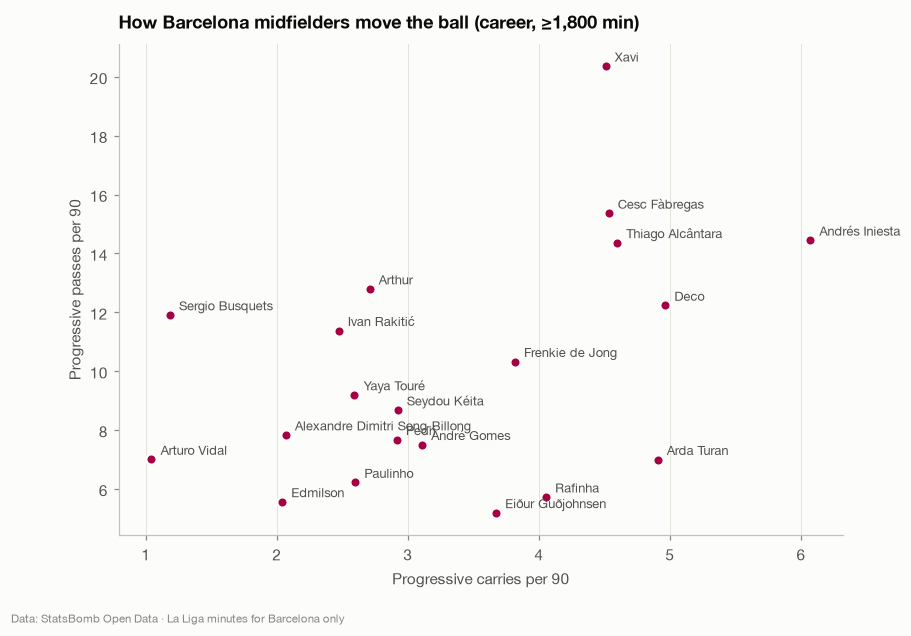

display_name,position_group,minutes,progressive_passes_p90,progressive_carries_p90,pass_completion
str,str,f64,f64,f64,f64
"""Xavi""","""CM""",21158.63,20.36,4.51,0.89
"""Cesc Fàbregas""","""CM""",5759.42,15.36,4.53,0.86
"""Andrés Iniesta""","""CM""",24551.22,14.45,6.07,0.88
"""Thiago Alcântara""","""CM""",3465.33,14.36,4.60,0.91
"""Arthur""","""CM""",2293.80,12.79,2.71,0.92
"""Deco""","""CM""",4605.38,12.23,4.96,0.79
"""Sergio Busquets""","""DM""",31270.48,11.91,1.18,0.91
"""Ivan Rakitić""","""CM""",14168.20,11.38,2.47,0.88
"""Frenkie de Jong""","""CM""",4882.05,10.32,3.82,0.92


In [7]:
mids = career.filter(pl.col("minutes") >= 1800, pl.col("position_group").is_in(["DM", "CM", "AM"]))
fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.scatter(mids["progressive_carries_p90"], mids["progressive_passes_p90"], s=46, color=style.BARCA,
           edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
for r in mids.iter_rows(named=True):
    ax.annotate(r["display_name"], (r["progressive_carries_p90"], r["progressive_passes_p90"]), xytext=(6, 3),
                textcoords="offset points", fontsize=8.5, color=style.INK_2)
ax.set_xlabel("Progressive carries per 90")
ax.set_ylabel("Progressive passes per 90")
ax.set_title("How Barcelona midfielders move the ball (career, ≥1,800 min)")
ax.grid(axis="both")
style.caption(ax, style.STATSBOMB_CREDIT + " · La Liga minutes for Barcelona only")
style.savefig(fig, "04_progression")
plt.show()
mids.select("display_name", "position_group", "minutes", "progressive_passes_p90", "progressive_carries_p90",
            "pass_completion").sort("progressive_passes_p90", descending=True)

Midfielders progress the ball in different proportions of passing and
carrying. **Busquets** is the clearest *passer*: solid progressive passing
with very few progressive carries. **Iniesta** is the archetypal *carrier*
among the long-serving midfielders. **Xavi** is exceptional because he is
high on both. The rating's progression pillar therefore counts passes and
carries together, so neither style is penalised.

## 5. Defending, adjusted for possession

Raw defensive counts punish players on possession-dominant teams: when
Barcelona hold the ball there is nothing to tackle. Possession-adjusted
counts (`padj_*`) scale each match by 0.5 / opponent possession.

In [8]:
league_1516 = player_season.aggregate(
    pm.filter(pl.col("season") == "2015/2016"), ["team", "player_id"]
).filter(pl.col("minutes") >= 900)
compare = league_1516.with_columns((pl.col("team") == "Barcelona").alias("barca")).group_by("barca").agg(
    pl.col("tackles_p90").median().alias("tackles_p90"),
    pl.col("padj_tackles_p90").median().alias("padj_tackles_p90"),
    pl.col("interceptions_p90").median().alias("interceptions_p90"),
    pl.col("padj_interceptions_p90").median().alias("padj_interceptions_p90"),
    pl.col("pressures_p90").median().alias("pressures_p90"),
    pl.col("padj_pressures_p90").median().alias("padj_pressures_p90"),
)
compare

barca,tackles_p90,padj_tackles_p90,interceptions_p90,padj_interceptions_p90,pressures_p90,padj_pressures_p90
bool,f64,f64,f64,f64,f64,f64
false,1.75,1.76,1.55,1.57,13.71,13.88
true,1.54,2.35,1.05,1.57,11.15,16.69


In 2015/16, the median Barcelona player made fewer raw tackles,
interceptions and pressures per 90 than the median player elsewhere in the
league. After possession adjustment the picture **flips**: per unit of
opponent possession, Barcelona's median player made *more* tackles and
pressures than the league median, and as many interceptions. Barcelona's
players did not defend less. They had less time without the ball. **The rating model therefore uses possession-adjusted
defensive metrics.**

## 6. Profiles by position

Median per-90 profile per position group (all player-seasons ≥ 900
minutes across every team in the data), the reference the rating model
compares players against.

In [9]:
all_seasons = player_season.aggregate(pm, ["season", "team", "player_id"]).filter(pl.col("minutes") >= 900)
profile_cols = ["npxg_p90", "xa_p90", "key_passes_p90", "progressive_passes_p90", "progressive_carries_p90",
                "box_entries_p90", "dribbles_completed_p90", "padj_tackles_p90", "padj_interceptions_p90",
                "padj_pressures_p90", "aerials_won_p90", "pass_completion"]
order = ["GK", "CB", "FB", "DM", "CM", "AM", "W", "ST"]
prof = (
    all_seasons.group_by("position_group")
    .agg(pl.len().alias("n"), *[pl.col(c).median() for c in profile_cols])
    .with_columns(pl.col("position_group").replace_strict({k: i for i, k in enumerate(order)}).alias("_o"))
    .sort("_o").drop("_o")
)
prof

position_group,n,npxg_p90,xa_p90,key_passes_p90,progressive_passes_p90,progressive_carries_p90,box_entries_p90,dribbles_completed_p90,padj_tackles_p90,padj_interceptions_p90,padj_pressures_p90,aerials_won_p90,pass_completion
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GK""",39,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.11,0.00,0.66
"""CB""",108,0.04,0.01,0.13,4.97,0.93,0.11,0.28,1.96,1.80,9.52,2.56,0.84
"""FB""",106,0.02,0.06,0.55,5.98,2.85,1.24,0.83,2.73,1.84,14.42,1.33,0.79
"""DM""",76,0.03,0.05,0.43,7.99,1.27,0.46,0.73,2.73,1.73,18.96,2.01,0.82
"""CM""",57,0.11,0.15,1.15,12.77,4.04,1.57,1.49,2.44,1.00,21.50,0.60,0.88
"""AM""",9,0.14,0.10,0.84,6.23,4.14,1.57,0.96,1.93,1.16,19.56,0.63,0.77
"""W""",114,0.18,0.18,1.29,4.77,5.48,2.72,1.91,1.55,0.93,16.61,0.73,0.75
"""ST""",61,0.40,0.13,0.88,2.51,2.86,1.70,1.22,0.88,0.39,14.28,1.71,0.73


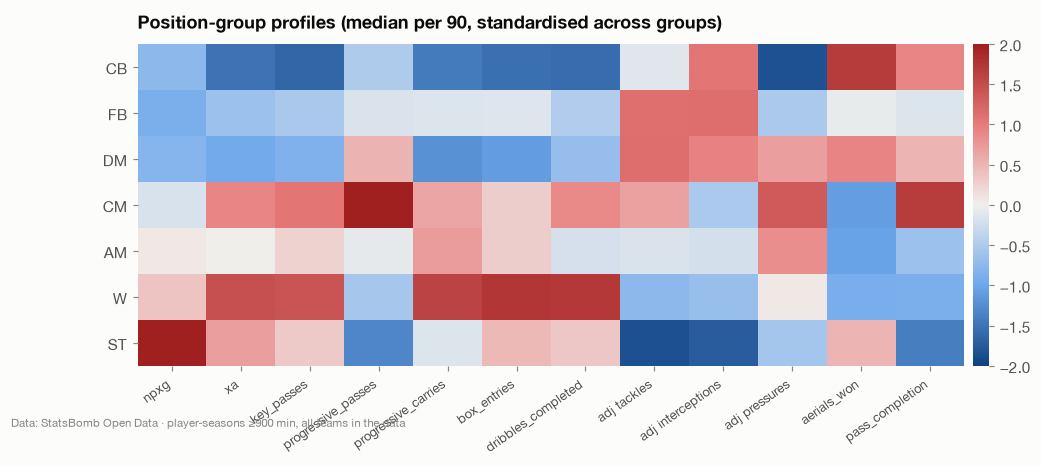

In [10]:
z = prof.filter(pl.col("position_group") != "GK")
mat = z.select(profile_cols).to_numpy()
mat = (mat - mat.mean(axis=0)) / mat.std(axis=0)
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(mat, cmap=style.DIVERGING, vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(z.height), z["position_group"].to_list())
ax.set_xticks(range(len(profile_cols)), [c.replace("_p90", "").replace("padj_", "adj ") for c in profile_cols],
              rotation=35, ha="right", fontsize=8.5)
ax.grid(False)
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.set_title("Position-group profiles (median per 90, standardised across groups)")
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cb.outline.set_visible(False)
style.caption(ax, style.STATSBOMB_CREDIT + " · player-seasons ≥900 min, all teams in the data")
style.savefig(fig, "04_position_profiles")
plt.show()

(The AM group is small, nine player-seasons, because most attacking
midfielders in this era are recorded as wingers or central midfielders. It
is merged with W into one family for the rating.)

Each group has a clear signature: centre-backs lead on aerials and
interceptions, full-backs on crosses and box entries from wide, defensive
midfielders on progressive passing and tackling, wingers on dribbles and
carries, strikers on npxG. A single, position-agnostic rating would reward
strikers for shooting and punish centre-backs for not shooting. The rating
has to be **position-specific**.

## 7. Messi across 17 seasons

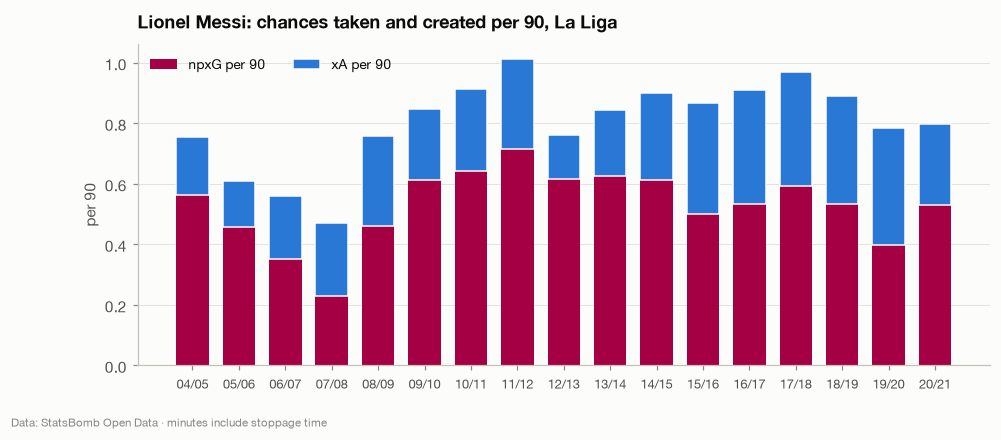

In [11]:
messi = seasons.filter(pl.col("display_name") == "Lionel Messi").sort("season")
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(messi.height)
ax.bar(x, messi["npxg_p90"], color=style.BARCA, width=0.7, label="npxG per 90")
ax.bar(x, messi["xa_p90"], bottom=messi["npxg_p90"], color=style.OPPONENT, width=0.7, label="xA per 90",
       edgecolor=style.SURFACE, linewidth=1)
ax.set_xticks(x, messi["season"].str.slice(2, 2) + "/" + messi["season"].str.slice(7, 2), fontsize=8.5)
ax.set_ylabel("per 90")
ax.set_title("Lionel Messi: chances taken and created per 90, La Liga")
ax.legend(loc="upper left", ncols=2)
style.caption(ax, style.STATSBOMB_CREDIT + " · minutes include stoppage time")
style.savefig(fig, "04_messi")
plt.show()

The shape of the career is visible: a winger's profile early on, an
extraordinary goal-scoring peak (2010/11-2012/13) and a steady shift
towards creation in the later seasons, with xA per 90 rising as npxG per 90
eased.

## 8. Barcelona players against the whole league

2015/16 is the only season with every club, so it is the only season where
a Barcelona player's percentile *within the league* can be computed
honestly.

In [12]:
metrics = ["npxg_p90", "xa_p90", "progressive_passes_p90", "progressive_carries_p90",
           "padj_interceptions_p90", "padj_pressures_p90"]
ranked = league_1516.with_columns(
    [(pl.col(m).rank("average").over("position_group") / pl.len().over("position_group") * 100).round(0)
     .alias(f"pct_{m}") for m in metrics]
)
ranked.filter(pl.col("team") == "Barcelona", pl.col("position_group") != "GK").sort("minutes", descending=True).select(
    "display_name", "position_group", "minutes", *[f"pct_{m}" for m in metrics]
).head(14)

display_name,position_group,minutes,pct_npxg_p90,pct_xa_p90,pct_progressive_passes_p90,pct_progressive_carries_p90,pct_padj_interceptions_p90,pct_padj_pressures_p90
str,str,f64,f64,f64,f64,f64,f64,f64
"""Luis Suárez""","""ST""",3272.62,98.00,100.00,79.00,83.00,36.00,33.00
"""Neymar""","""W""",3163.10,96.00,100.00,68.00,100.00,11.00,61.00
"""Sergio Busquets""","""DM""",3005.33,4.00,80.00,87.00,49.00,36.00,96.00
"""Lionel Messi""","""W""",2829.82,99.00,99.00,100.00,93.00,3.00,3.00
"""Javier Mascherano""","""CB""",2802.72,8.00,82.00,100.00,98.00,35.00,100.00
"""Jordi Alba""","""FB""",2681.83,73.00,94.00,97.00,22.00,37.00,79.00
"""Gerard Piqué""","""CB""",2672.02,92.00,74.00,98.00,100.00,15.00,68.00
"""Ivan Rakitić""","""CM""",2665.92,85.00,54.00,46.00,31.00,62.00,92.00
"""Andrés Iniesta""","""CM""",2327.37,46.00,62.00,100.00,85.00,8.00,62.00


Percentiles within position group are an intuitive way to present a
player: "top 5% of La Liga midfielders for progressive passes". The rating
(BIPR) builds on exactly this idea, with a reference population large
enough to be stable.

## Findings

1. **Per-90 rates need ≥ 900 minutes** to be meaningful; below that, show
   the data with a warning rather than a rating.
2. **Barcelona's attack is Messi-shaped**: the highest combined npxG + xA of
   any player-season in the data, and about half of the team's finishing
   over-performance.
3. **Finishing over-performance does not persist season to season**, but it
   is real over a career (Messi). xG is the stable short-term signal.
4. **Midfielders progress the ball in two distinct ways**: passers and
   carriers. The rating's "progression" pillar must count both.
5. **Raw defensive counts mislead for a possession team.** Possession
   adjustment is required.
6. **Position groups have distinct signatures**, so the rating must be
   position-specific.

Next: where players act on the pitch (`05_spatial_eda`).